In [27]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
from src.metamaterial.physics.coupling.full_retarded_old import L_parallel as L_par_full
from src.metamaterial.physics.coupling.full_retarded_old import L_orthogonal as L_ort_full
from src.metamaterial.physics.coupling.full_retarded import L_parallel as L_par_sum
from src.metamaterial.physics.coupling.full_retarded import L_orthogonal as L_ort_sum
from src.metamaterial.physics.coupling.approx_retarded import L_parallel as L_par_rec
from src.metamaterial.physics.coupling.approx_retarded import L_orthogonal as L_ort_rec

In [28]:
plt.rcParams.update({
    'figure.figsize': (6.5, 4.3),
    'font.family': 'serif',
    'mathtext.fontset': 'dejavusans',
    'axes.titlesize': 17,
    'axes.labelsize': 17,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.size': 16,
    'legend.fontsize': 17,
    'legend.loc': 'best',
    'legend.fancybox': False,
    'legend.shadow': False,
    'legend.frameon': True,
    'figure.dpi': 500,
    'text.usetex': False,
    'lines.markersize': 8,
    'lines.linewidth': 3,
    'lines.markeredgewidth': 1,
    'lines.markeredgecolor': 'black',
    'scatter.edgecolors': 'black',
    'patch.edgecolor': 'black',
    'axes.prop_cycle': plt.cycler(color =['red', 'green', 'blue', 'magenta', 'yellow', 'black', 'cyan']),
})

## error and speedup

In [29]:
r1 = 4.935 * 10 ** -3
r2=r1
dx = np.linspace(3*r1, 50*r1, 100)
dy = np.zeros_like(dx)
dz = dx
omega = 2*np.pi*1e7

In [30]:
t0 = time.time()
L_par_full_values = np.asarray([L_par_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t1 = time.time()
L_par_sum_values = np.asarray([L_par_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t2 = time.time()
L_ort_full_values = np.asarray([L_ort_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t3 = time.time()
L_ort_sum_values = np.asarray([L_ort_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t4 = time.time()

In [31]:
print(f"Speedup parallel: {(t1 - t0) / (t2 - t1)}")
print(f"Speedup orthogonal: {(t3 - t2) / (t4 - t3)}")

Speedup parallel: 15.374621727671332
Speedup orthogonal: 25.35510334027145


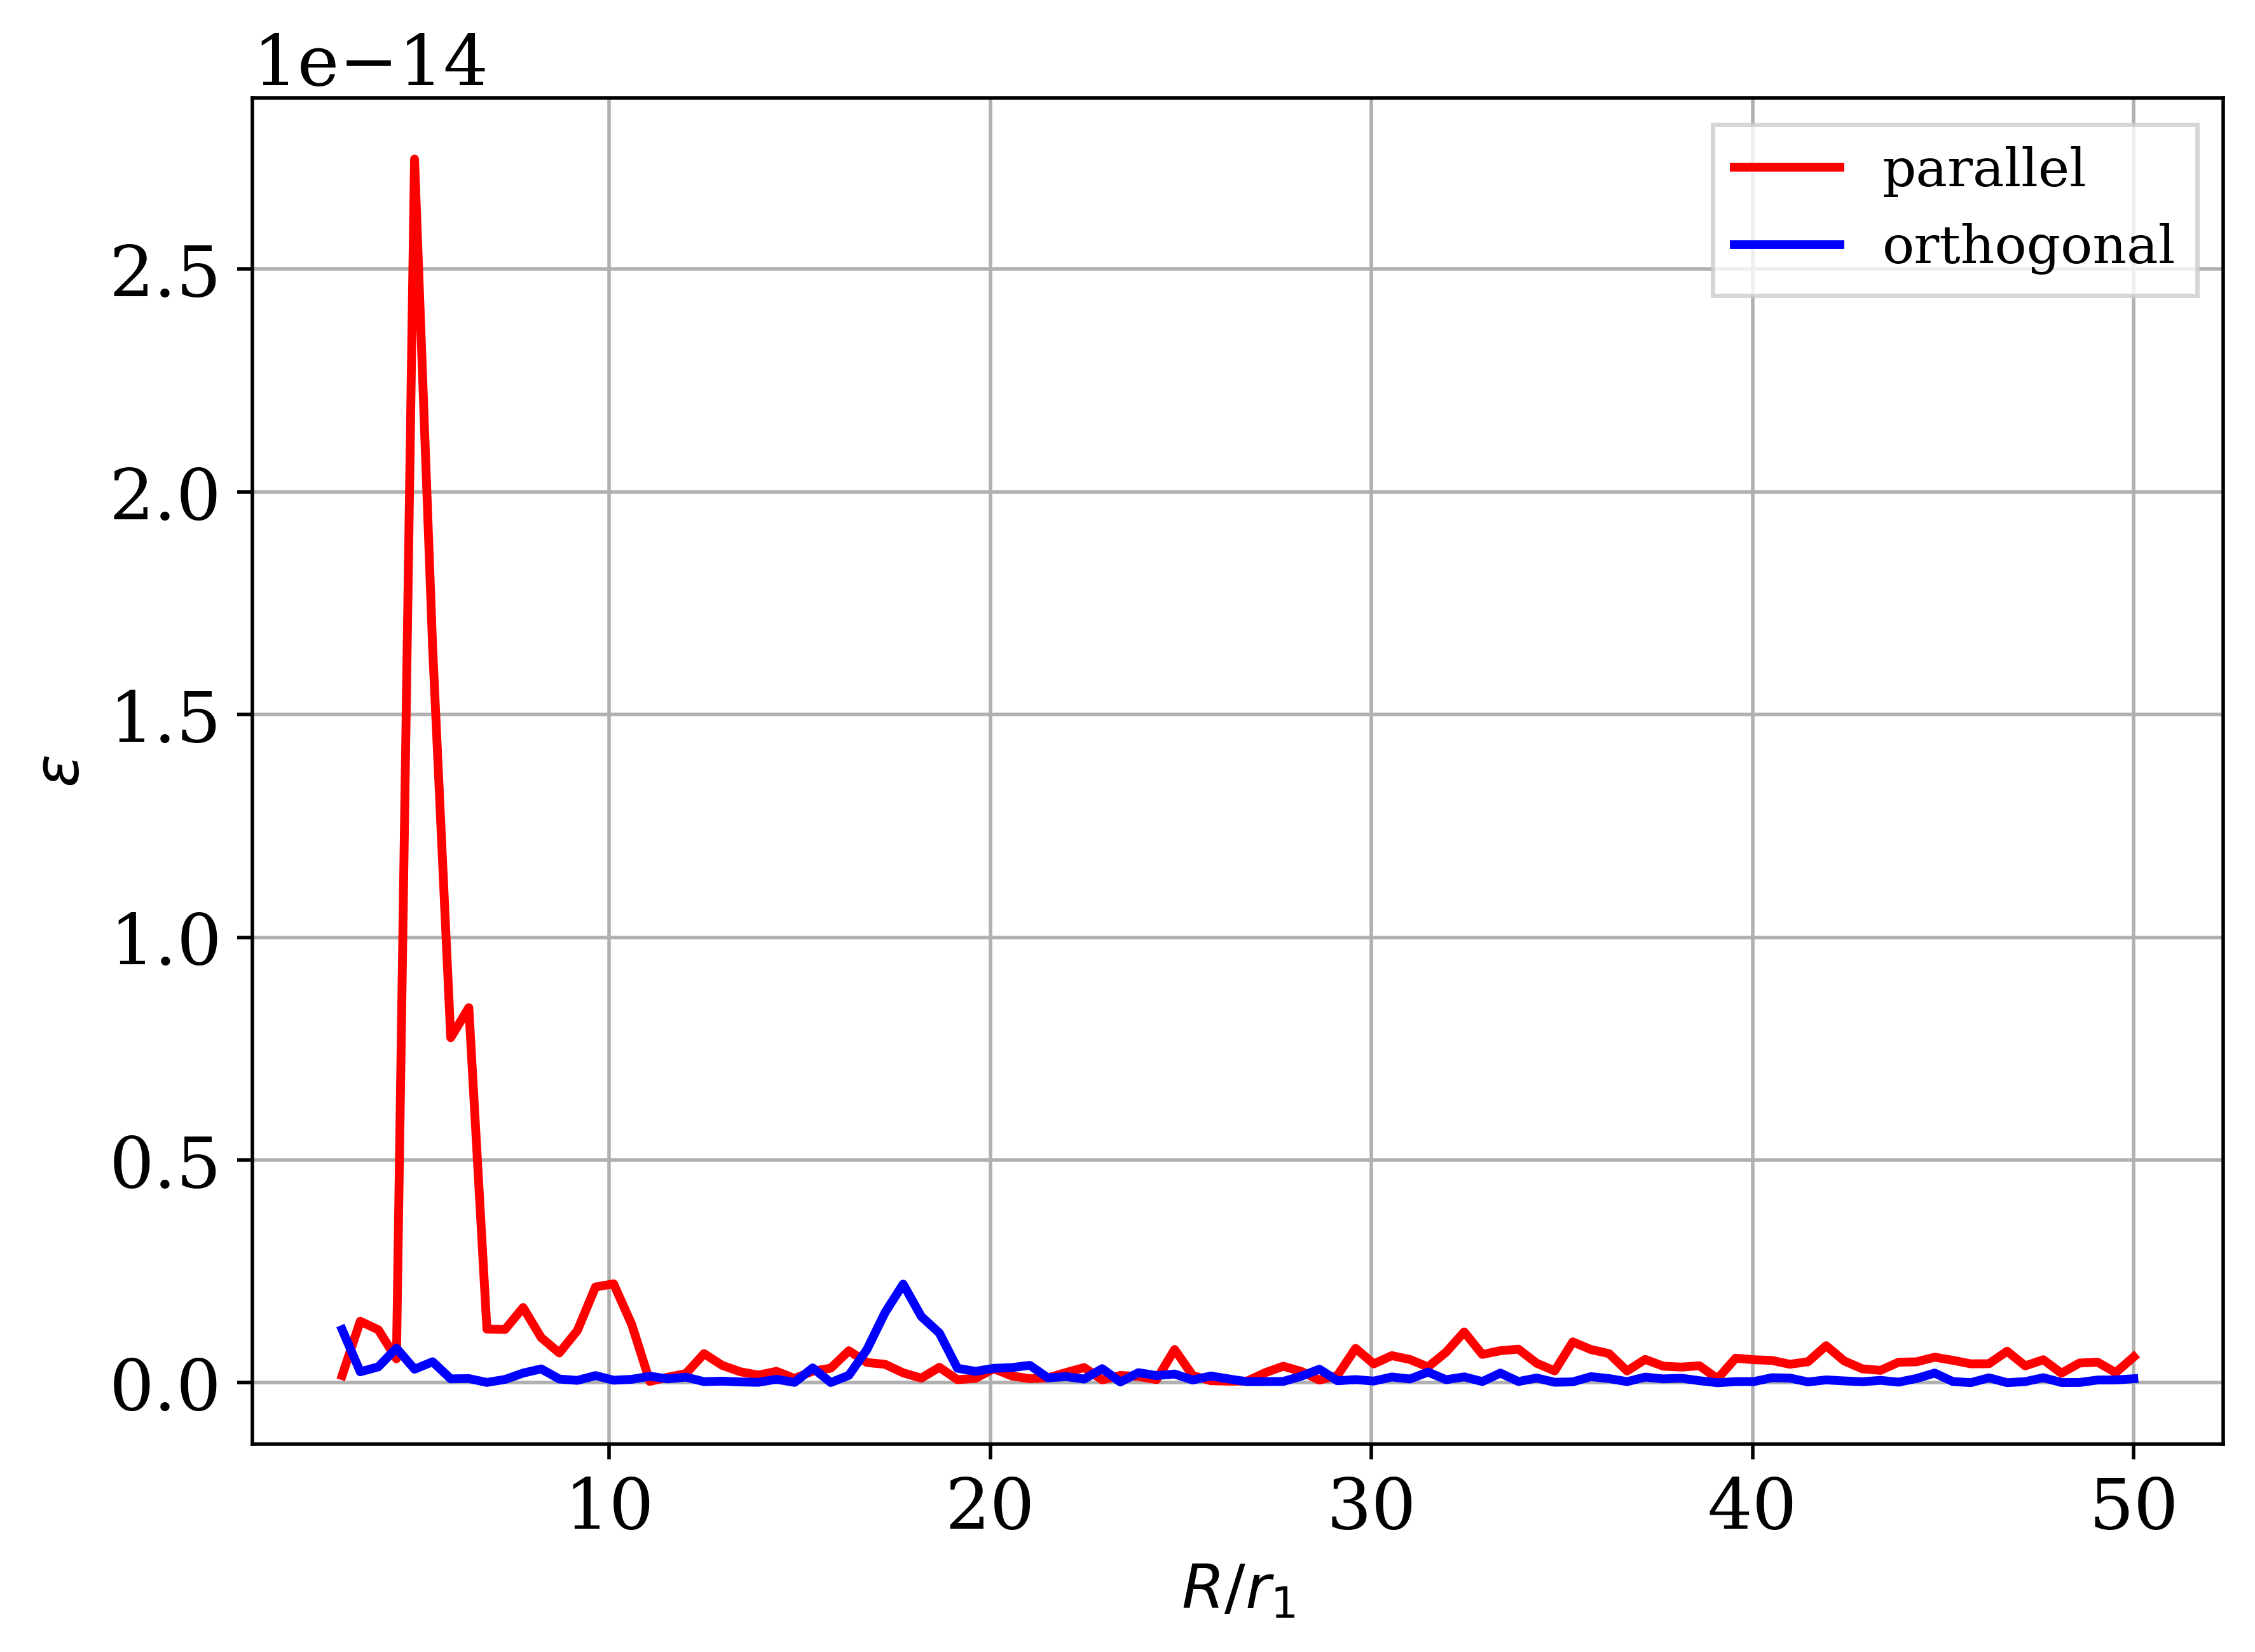

In [32]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(dx/r1, np.abs((L_par_full_values-L_par_sum_values)/(L_par_full_values+1e-5)), label='parallel', color='red', linewidth=2)
ax.plot(dx/r1, np.abs((L_ort_full_values-L_ort_sum_values)/(L_ort_full_values+1e-5)), label='orthogonal', color='blue', linewidth=2)
ax.set_xlabel('$R/r_1$', fontsize=14)
ax.set_ylabel(r'$\varepsilon$', fontsize=14)
ax.legend(fontsize=12)
plt.grid()
plt.show()

## Time estimation

In [33]:
r1 = 4.935 * 10 ** -3
r2=r1
dx = np.linspace(3*r1, 50*r1, 100)
dy = np.linspace(3*r1, 50*r1, 100)
dz = np.ones_like(dx)*r1
omega = 2*np.pi*1e7
repeats = 4

In [34]:
times_full = np.empty((2, repeats))
times_sum = np.empty((2, repeats))
times_rec = np.empty((2, repeats))

for rep in range(repeats):
    t0 = perf_counter()
    L_par_full_values = np.asarray([L_par_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_full[0, rep] = perf_counter() - t0
    t1 = perf_counter()
    L_par_sum_values = np.asarray([L_par_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_sum[0, rep] = perf_counter() - t1
    t2 = perf_counter()
    L_par_rec_values = np.asarray([L_par_rec(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_rec[0, rep] = perf_counter() - t2
    t3 = perf_counter()
    L_ort_full_values = np.asarray([L_ort_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_full[1, rep] = perf_counter() - t3
    t4 = perf_counter()
    L_ort_sum_values = np.asarray([L_ort_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_sum[1, rep] = perf_counter() - t4
    t5 = perf_counter()
    L_ort_rec_values = np.asarray([L_ort_rec(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_rec[1, rep] = perf_counter() - t5



print(f'Parallel full retarded time (scipy.integrate): {np.min(times_full[0, :]):.6f} seconds')
print(f'Parallel full retarded time (trapezoidal rule): {np.min(times_sum[0, :]):.6f} seconds')
print(f'Parallel approx retarded time: {np.mean(times_rec[0, :]):.6f} seconds')

print(f'Orthogonal full retarded time (scipy.integrate): {np.min(times_full[1, :]):.6f} seconds')
print(f'Orthogonal full retarded time (trapezoidal rule): {np.min(times_sum[1, :]):.6f} seconds')
print(f'Orthogonal approx retarded time: {np.mean(times_rec[1, :]):.6f} seconds')

Parallel full retarded time (scipy.integrate): 5.720611 seconds
Parallel full retarded time (trapezoidal rule): 0.255576 seconds
Parallel approx retarded time: 0.043321 seconds
Orthogonal full retarded time (scipy.integrate): 4.902515 seconds
Orthogonal full retarded time (trapezoidal rule): 0.254967 seconds
Orthogonal approx retarded time: 0.202778 seconds


<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
C:\Users\pmish\AppData\Local\Temp\ipykernel_27192\856735307.py:2: SyntaxWarning: invalid escape sequence '\ '
  methods = ['$L_{int\ par}$', '$L_{sum\ par}$', '$L_{rec\ par}$', '$L_{int\ ort}$', '$L_{sum\ ort}$', '$L_{rec\ ort}$']
C:\Users\pmish\AppData\Local\Temp\ipykernel_27192\856735307.py:2: SyntaxWarning: invalid escape sequence '\ '
  methods = ['$L_{int\ par}$', '$L_{sum\ par}$', '$L_{rec\ 

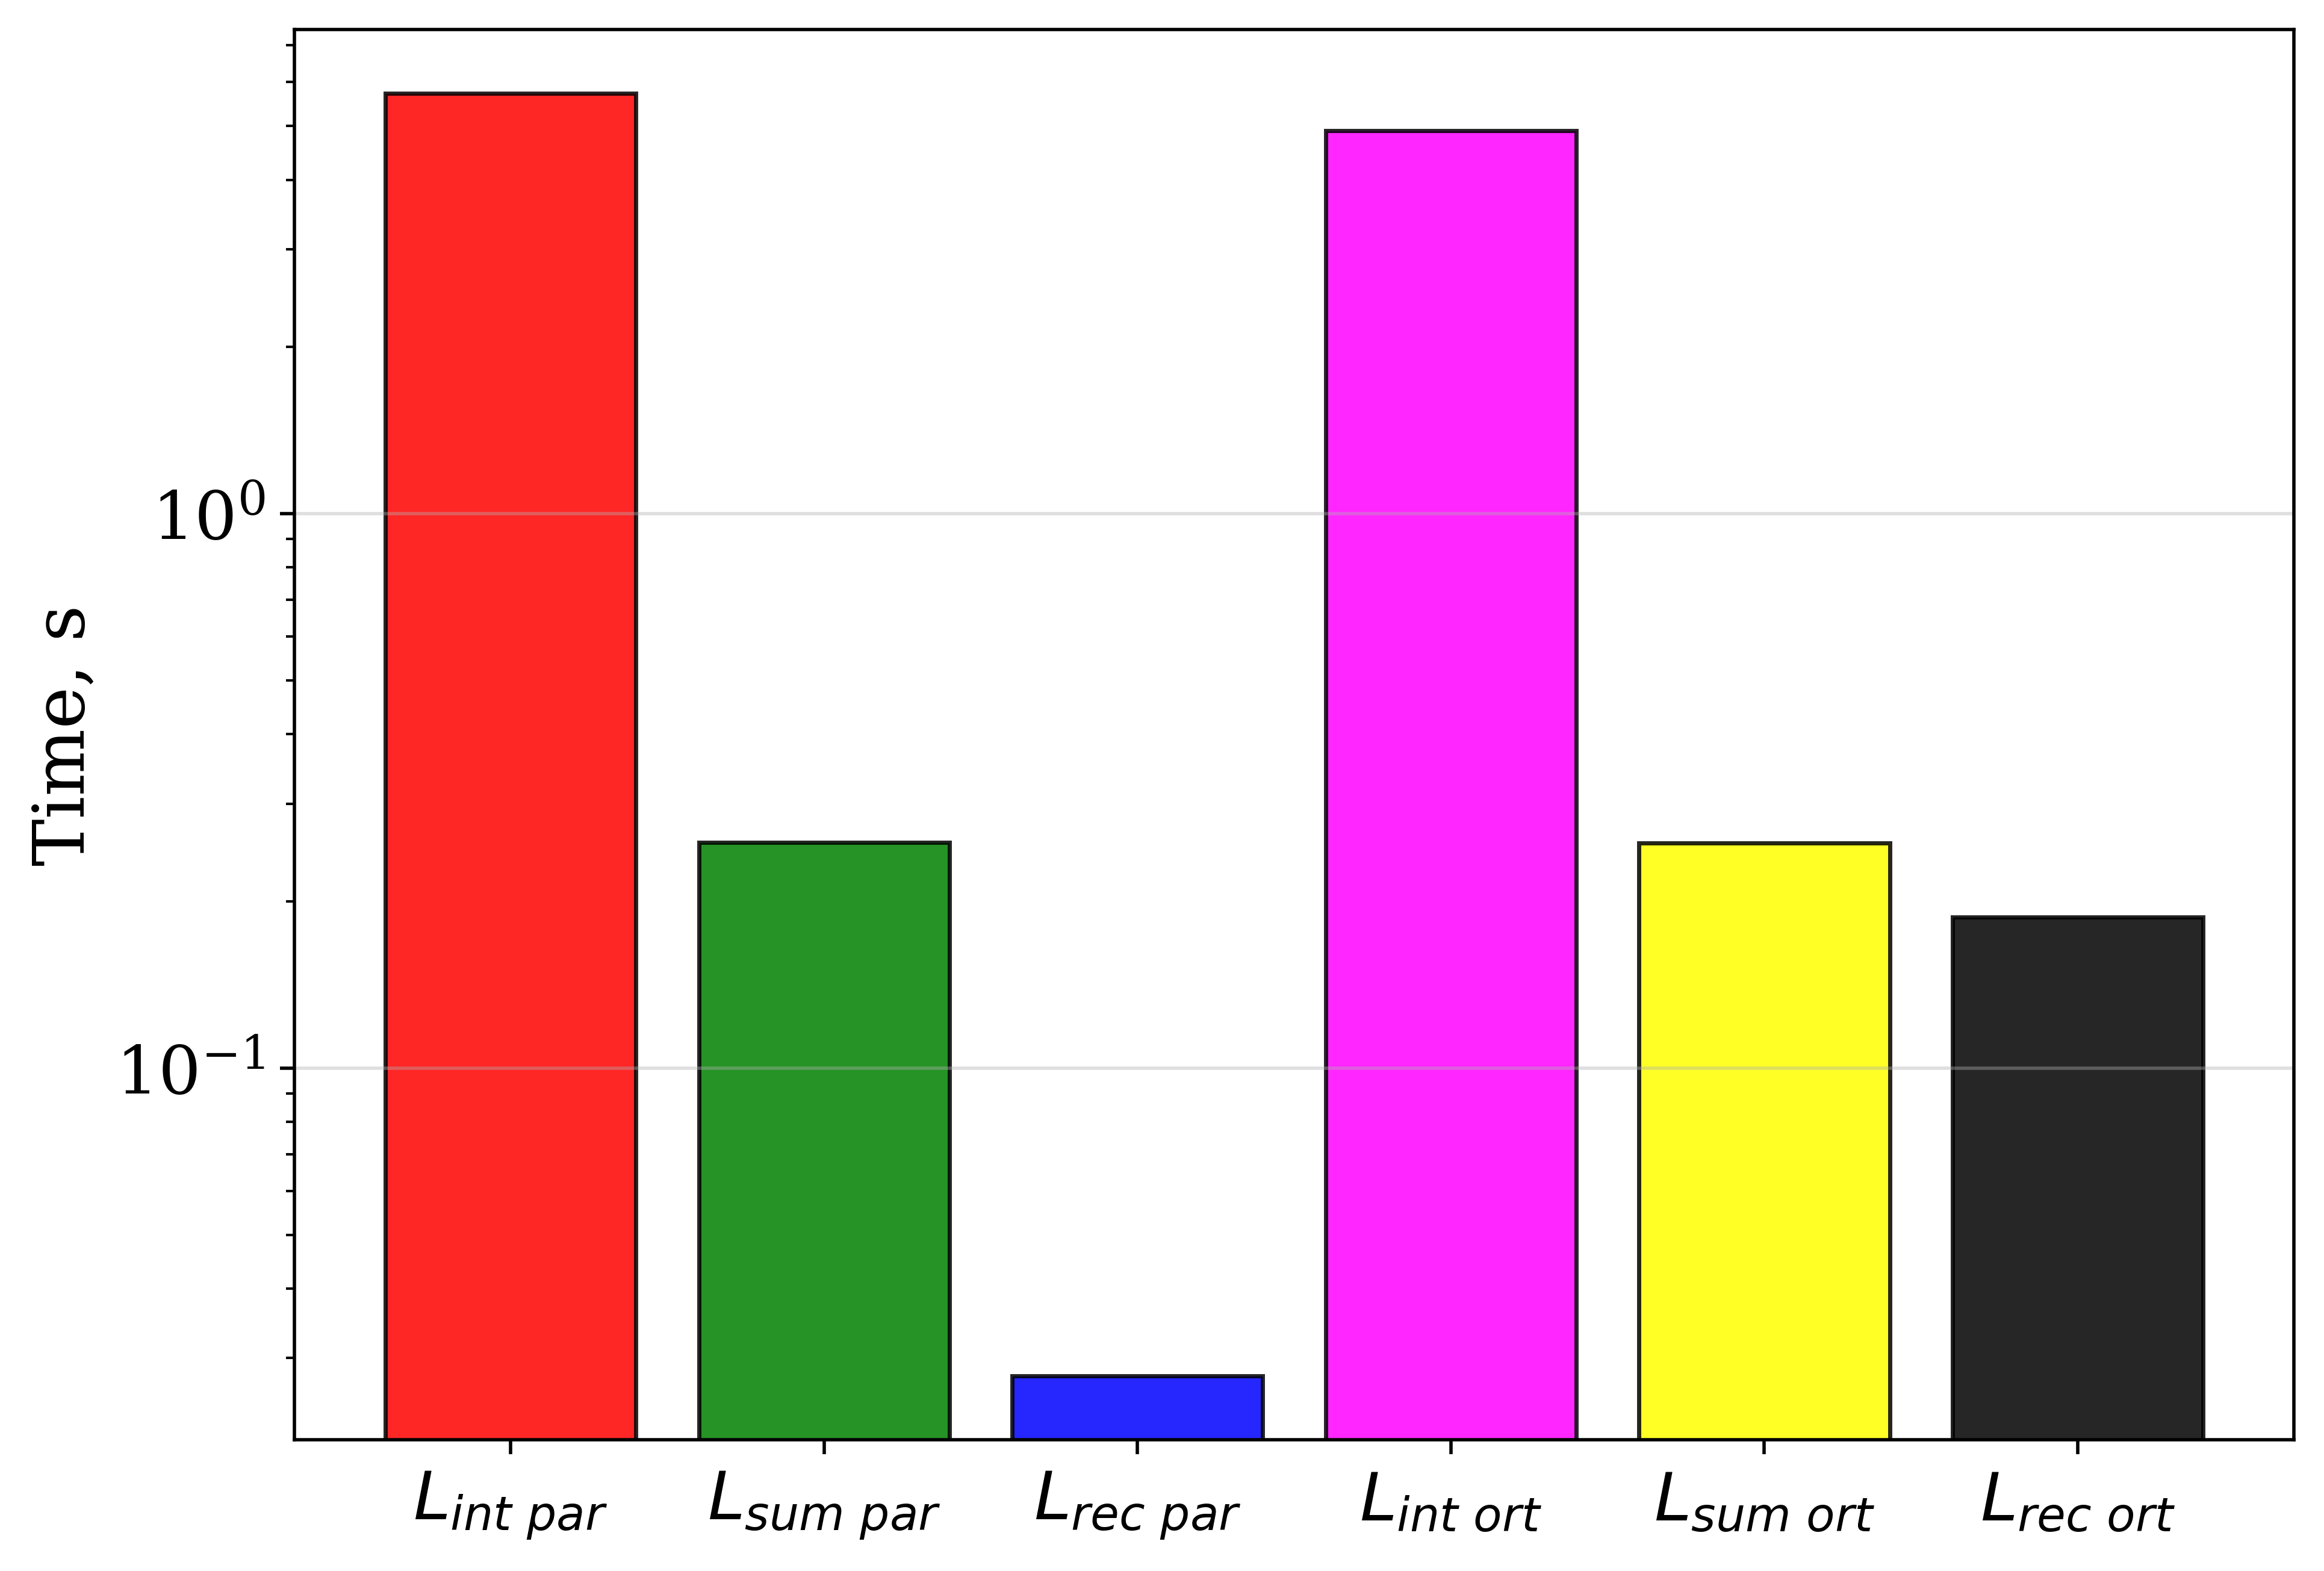

In [41]:
fig, ax = plt.subplots(figsize=(8, 5.5))
methods = ['$L_{int\ par}$', '$L_{sum\ par}$', '$L_{rec\ par}$', '$L_{int\ ort}$', '$L_{sum\ ort}$', '$L_{rec\ ort}$']
times   = [np.min(times_full[0,:]),np.min(times_sum[0,:]),np.min(times_rec[0,:]),
           np.min(times_full[1,:]),np.min(times_sum[1,:]),np.min(times_rec[1,:])]
colors = ['red', 'green', 'blue', 'magenta', 'yellow', 'black']
ax.bar(methods, times, color = colors, edgecolor='black', alpha=0.85)
ax.set_ylabel('Time, s')
ax.set_yscale('log')
ax.grid(True, axis='y', alpha=0.4)
plt.tight_layout()
plt.show()
